# 5 · Gradient boosting

```{math}
F_m(x) = F_{m-1}(x) + \eta\, h_m(x)
```

**Family:** tree models · **Task:** classification

Where a forest grows trees independently, boosting grows them in sequence. The model
$F$ is a score in log-odds; $p = \sigma(F)$. Each new small tree $h_m$ is fitted to the
negative gradient of the log-loss, which for this loss is simply the residual
$r_i = y_i - \sigma(F_{m-1}(x_i))$: what the model so far still gets wrong. The
learning rate $\eta$ shrinks each step. The video counts this down, "8 trees · 2
mistakes", then "60 trees · 0 mistakes".

## Imports

`ml8` is the book's own package; [The sample data](00_sample_data.ipynb) explains how it is
imported. This chapter uses:

| File | What this chapter uses |
|---|---|
| `ml8/data.py` | `data.grid`: the grid of points behind every decision surface<br>`data.moons_arrays`: two-moons train and test arrays (`X_train, y_train, X_test, y_test`)<br>`data.SEED`: the shared random seed |
| `ml8/scratch.py` | `scratch.sigmoid`: the function $\sigma(z)$ |
| `ml8/models.py` | `models.boosting`: a scikit-learn `GradientBoostingClassifier` with the book's settings<br>`models.BOOST_STAGES`: the boosting stages to compare |
| `ml8/plotting.py` | `P.plot_surface`: draws a decision surface and the points<br>the palette (`P.FG`, `P.GREEN`) |

In [1]:
# ml8 sits one folder above notebooks/, so put that folder on Python's search path
import sys
sys.path.insert(0, "..")

# Installed packages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor

# The book's own modules
from ml8 import data              # ml8/data.py: the seeded sample datasets
from ml8 import models            # ml8/models.py: shared model settings
from ml8 import plotting as P     # ml8/plotting.py: colours and plot helpers
from ml8 import scratch           # ml8/scratch.py: the from-scratch formulas

P.use_style()  # the dark style used by every figure
pd.set_option("display.precision", 4)

In [2]:
Xtr, ytr, Xte, yte = data.moons_arrays()
gb = models.boosting().fit(Xtr, ytr)
print(gb)

GradientBoostingClassifier(learning_rate=0.3, n_estimators=60, random_state=7)


## Boosting from scratch

Start from the log-odds of the class balance. Then, for each round: fit a depth-3
regression tree to the residuals $r_i$, replace each leaf's value with a Newton step
$\gamma_\ell = \sum_{i\in\ell} r_i \,/\, \sum_{i\in\ell} p_i(1-p_i)$, and add $\eta\,\gamma$.
Without the Newton step the leaves hold raw probability residuals (at most ±1), which are
far too timid as log-odds updates. This is the algorithm scikit-learn implements, so the
mistake counts should track closely.

In [3]:
def boost_scratch(X, y, n_trees=60, eta=0.3, depth=3):
    F = np.full(len(y), np.log(y.mean() / (1 - y.mean())))
    trees, mistakes = [], []
    for m in range(n_trees):
        p = scratch.sigmoid(F)
        r = y - p                                        # negative gradient of log-loss
        h = DecisionTreeRegressor(max_depth=depth, criterion="squared_error", random_state=data.SEED).fit(X, r)
        leaf = h.apply(X)
        gamma = {l: r[leaf == l].sum() / max((p * (1 - p))[leaf == l].sum(), 1e-12) for l in np.unique(leaf)}
        F = F + eta * np.array([gamma[l] for l in leaf])  # Newton step per leaf
        trees.append((h, gamma))
        mistakes.append(int(np.sum((F > 0) != y)))
    return trees, mistakes

_, scratch_mistakes = boost_scratch(Xtr, ytr)
sk_mistakes = [int(np.sum(p != ytr)) for p in gb.staged_predict(Xtr)]
pd.DataFrame({"from scratch": scratch_mistakes, "scikit-learn": sk_mistakes},
             index=pd.Index(range(1, 61), name="trees")).loc[models.BOOST_STAGES].T

trees,1,2,3,5,8,12,20,30,45,60
from scratch,23,23,22,20,16,14,7,2,0,0
scikit-learn,23,23,22,20,16,14,7,2,0,0


## Watching the mistakes disappear

Ringed points are misclassified training points at that stage.

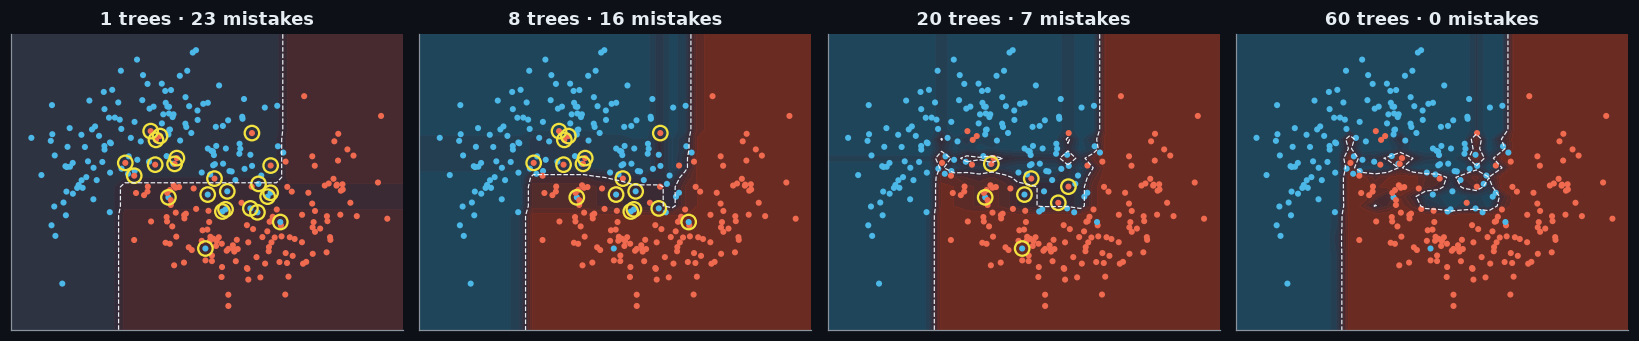

In [4]:
stages = [1, 8, 20, 60]
probas = list(gb.staged_predict_proba(data.grid()[2]))
preds = list(gb.staged_predict(Xtr))
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, s in zip(axes, stages):
    wrong = np.flatnonzero(preds[s - 1] != ytr)
    P.plot_surface(ax, probas[s - 1][:, 1], Xtr, ytr, highlight=wrong, title=f"{s} trees · {len(wrong)} mistakes")
plt.tight_layout()

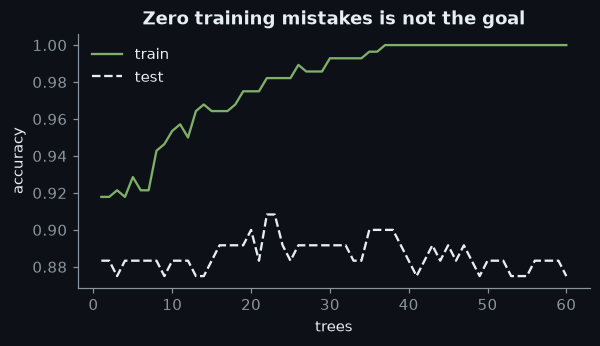

In [5]:
test_acc = [np.mean(p == yte) for p in gb.staged_predict(Xte)]
train_acc = [np.mean(p == ytr) for p in gb.staged_predict(Xtr)]
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(1, 61), train_acc, c=P.GREEN, label="train")
ax.plot(range(1, 61), test_acc, c=P.FG, ls="--", label="test")
ax.set_xlabel("trees"); ax.set_ylabel("accuracy"); ax.legend(frameon=False)
ax.set_title("Zero training mistakes is not the goal");

Training mistakes fall to zero, but test accuracy stops improving well before that and
ends lower than it was midway: the last trees are fitting noise in the training points. In practice you pick the number of trees on a
validation set (`n_iter_no_change` in scikit-learn) or lower $\eta$ and add more trees.

**Try it:** set `learning_rate=0.05` and `n_estimators=300` in `models.boosting`.